# Android App Market Analysis

## 1. Introduction

The Android app market contains applications across various categories, including entertainment, education, business, health, and lifestyle. Analyzing app data helps identify market trends, popular categories, user preferences, and factors associated with app ratings and installations.

This project explores Google Play Store application data using Python, Pandas, Matplotlib, and Seaborn. It also examines user reviews to understand sentiment and customer feedback.

## 2. Objectives

- Analyze the distribution of applications across categories.
- Examine app ratings, reviews, installations, and prices.
- Compare free and paid applications.
- Identify popular app categories and market trends.
- Analyze user reviews and sentiment.
- Visualize key findings using appropriate charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

## 3. Loading the Datasets

Loading datasets is the first step in the data analysis process. The Pandas library provides the `read_csv()` function to import CSV files into DataFrames for easy manipulation and analysis.

In this project, two datasets are used. The Google Play Store dataset contains application details such as category, rating, reviews, installations, price, and content rating. The user reviews dataset contains customer feedback, sentiment labels, sentiment polarity, and sentiment subjectivity.

The `head()` function displays the first five rows of each dataset, providing an initial understanding of their structure and contents. These datasets will be used for further data cleaning, exploratory data analysis, visualization, and sentiment analysis.

In [3]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("Google Play Store Dataset:")
display(apps.head())

print("\nUser Reviews Dataset:")
display(reviews.head())

Google Play Store Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



User Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


### 4. Understanding the Datasets

Understanding the structure and characteristics of a dataset is an important step in data analysis. The Google Play Store dataset contains information about applications, including their categories, ratings, reviews, installation counts, prices, and content ratings.

The user reviews dataset contains translated reviews, sentiment labels, sentiment polarity, and sentiment subjectivity. These attributes help analyze user opinions and satisfaction with applications.

Examining the dimensions, column names, and data types helps understand the available information and identify potential data quality issues before performing further analysis.

In [4]:
print("Google Play Store Dataset Shape:", apps.shape)
print("User Reviews Dataset Shape:", reviews.shape)

print("\nGoogle Play Store Columns:")
print(apps.columns.tolist())

print("\nUser Reviews Columns:")
print(reviews.columns.tolist())

print("\nGoogle Play Store Data Types:")
print(apps.dtypes)

print("\nUser Reviews Data Types:")
print(reviews.dtypes)

Google Play Store Dataset Shape: (10841, 13)
User Reviews Dataset Shape: (64295, 5)

Google Play Store Columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

User Reviews Columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']

Google Play Store Data Types:
App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

User Reviews Data Types:
App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object


### 5. Checking Missing Values and Duplicate Records

Data quality assessment is an important step in data preprocessing. Missing values may affect statistical calculations and visualizations, while duplicate records may lead to inaccurate analysis.

In this step, the `isnull().sum()` function identifies the number of missing values in each column, and the `duplicated().sum()` function counts duplicate rows in both datasets.

This assessment helps determine whether data cleaning is required before proceeding with exploratory data analysis. Missing values and duplicates will be handled based on their nature and relevance to the analysis.

In [5]:
print("Missing Values in Google Play Store Dataset:")
print(apps.isnull().sum())

print("\nDuplicate Rows in Google Play Store Dataset:")
print(apps.duplicated().sum())

print("\nMissing Values in User Reviews Dataset:")
print(reviews.isnull().sum())

print("\nDuplicate Rows in User Reviews Dataset:")
print(reviews.duplicated().sum())

Missing Values in Google Play Store Dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Duplicate Rows in Google Play Store Dataset:
483

Missing Values in User Reviews Dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

Duplicate Rows in User Reviews Dataset:
33616


### 6.Data Cleaning and Preprocessing

Data cleaning is an essential step in data analysis that improves data quality and reliability. Real-world datasets may contain missing values, duplicate records, inconsistent formats, and invalid entries.

In the Google Play Store dataset, the `Rating` column may contain missing values, while `Reviews`, `Installs`, and `Price` may be stored as text because they contain special characters. The `Size` column may also contain values expressed in different units.

This step involves removing duplicate applications, handling missing values, correcting data types, and converting numerical attributes into usable formats. These preprocessing operations prepare the dataset for accurate statistical analysis and visualization.

In [6]:
# Remove duplicate application records
apps.drop_duplicates(inplace=True)

# Convert Rating to numeric
apps["Rating"] = pd.to_numeric(apps["Rating"], errors="coerce")

# Remove invalid ratings above 5
apps.loc[apps["Rating"] > 5, "Rating"] = np.nan

# Clean and convert Reviews
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")

# Clean and convert Installs
apps["Installs"] = pd.to_numeric(
    apps["Installs"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

# Clean and convert Price
apps["Price"] = pd.to_numeric(
    apps["Price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)

# Remove rows missing essential analysis fields
apps.dropna(subset=["App", "Category", "Rating", "Reviews", "Installs", "Price"], inplace=True)

print("Cleaned Google Play Store Dataset Shape:", apps.shape)
print("\nRemaining Missing Values:")
print(apps[["App", "Category", "Rating", "Reviews", "Installs", "Price"]].isnull().sum())

print("\nRemaining Duplicate Rows:", apps.duplicated().sum())

Cleaned Google Play Store Dataset Shape: (8892, 13)

Remaining Missing Values:
App         0
Category    0
Rating      0
Reviews     0
Installs    0
Price       0
dtype: int64

Remaining Duplicate Rows: 0


### Observation

The Google Play Store dataset was cleaned by removing duplicate records, converting important columns into numerical formats, and handling invalid or missing values in essential fields. These steps improve data consistency and prepare the dataset for further analysis of app ratings, categories, installations, reviews, and prices.

The final dataset dimensions indicate the number of records retained after preprocessing. The remaining missing-value and duplicate checks help verify the effectiveness of the cleaning process.

### 7.App Category Distribution Analysis

The Google Play Store contains applications belonging to different categories, such as Education, Entertainment, Business, Finance, and Games. Analyzing category distribution helps understand which types of applications are most common in the market.

In this step, the `value_counts()` function counts the number of applications in each category. A bar chart is used to visualize the distribution and compare the number of applications across categories.

This analysis helps identify highly represented categories and categories with fewer applications, providing an initial understanding of the Android app market.

Number of Applications by Category:


,App Count
Category,
FAMILY,1718
GAME,1074
TOOLS,734
PRODUCTIVITY,334
FINANCE,317
PERSONALIZATION,310
COMMUNICATION,307
LIFESTYLE,305
PHOTOGRAPHY,304


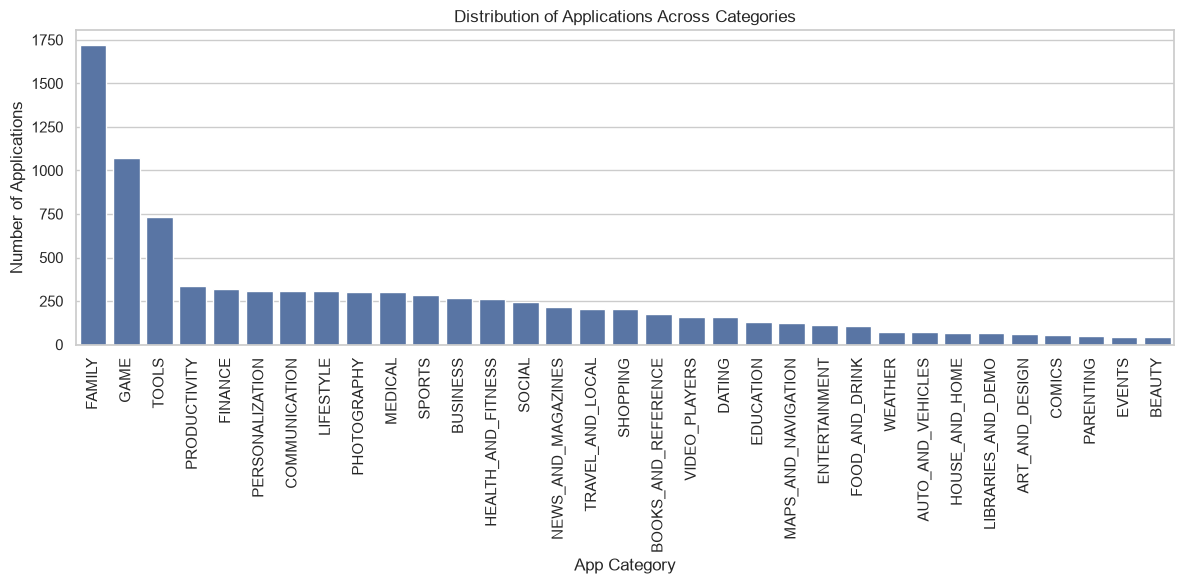

In [11]:
category_counts = apps_clean["Category"].value_counts()

print("Number of Applications by Category:")
display(category_counts.to_frame("App Count"))

plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Distribution of Applications Across Categories")
plt.xlabel("App Category")
plt.ylabel("Number of Applications")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Observation

The bar chart shows the number of applications available in each Google Play Store category. Categories with taller bars contain more applications, while shorter bars indicate fewer applications.

The distribution helps identify the most common and least represented app categories. These findings provide a foundation for further analysis of app ratings, installations, pricing, and user sentiment across different categories.

### 8.App Rating Distribution Analysis

App ratings represent users' overall satisfaction with applications on the Google Play Store. Ratings generally range from 1 to 5, with higher ratings indicating greater user satisfaction.

In this analysis, the distribution of app ratings is examined using a histogram and a Kernel Density Estimate (KDE) curve. The histogram shows the frequency of apps within different rating ranges, while the KDE curve illustrates the overall distribution pattern.

This analysis helps identify common rating ranges and understand the general rating pattern of applications.

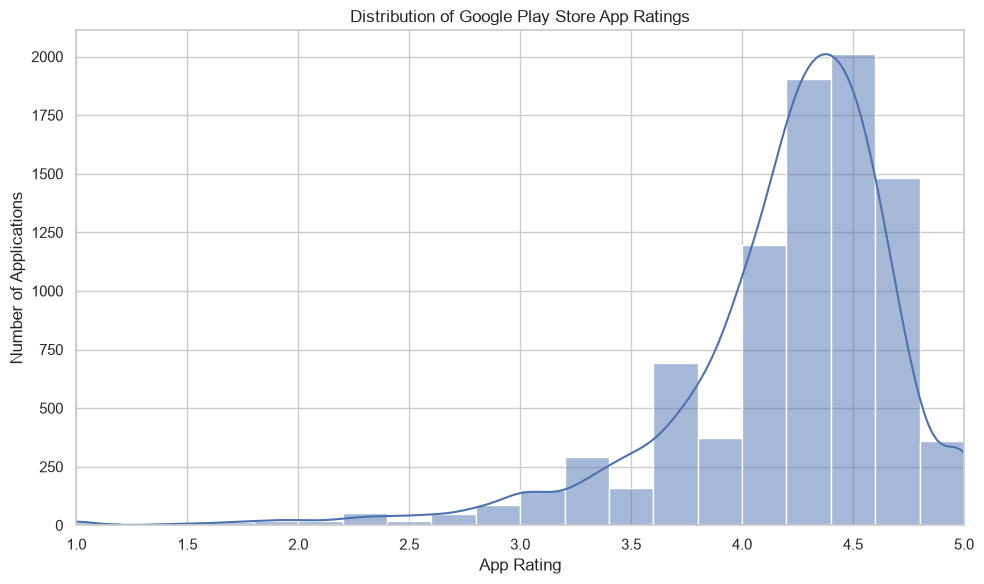

Average App Rating: 4.19
Median App Rating: 4.3


In [12]:
rating_data = apps_clean["Rating"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    rating_data,
    bins=20,
    kde=True
)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("App Rating")
plt.ylabel("Number of Applications")
plt.xlim(1, 5)
plt.tight_layout()
plt.show()

print("Average App Rating:", round(rating_data.mean(), 2))
print("Median App Rating:", round(rating_data.median(), 2))

### Observation

The histogram illustrates the distribution of app ratings, showing which rating ranges contain the largest number of applications. The KDE curve provides a smoothed representation of the distribution.

The average and median ratings summarize the central tendency of app ratings. These results help assess the general rating pattern of applications in the Google Play Store.

### 9.Average App Rating by Category

Analyzing average app ratings by category helps compare user satisfaction across different types of applications. The mean rating is calculated for each category using the available valid ratings.

A bar chart is used to visualize the average rating of each category. Categories with higher average ratings may indicate greater user satisfaction, while lower average ratings may highlight areas for improvement.

This analysis helps understand rating differences across the Google Play Store categories.

Average App Rating by Category:


,Average Rating
Category,
EVENTS,4.44
EDUCATION,4.38
ART_AND_DESIGN,4.36
BOOKS_AND_REFERENCE,4.35
PERSONALIZATION,4.33
PARENTING,4.30
GAME,4.28
BEAUTY,4.28
HEALTH_AND_FITNESS,4.26


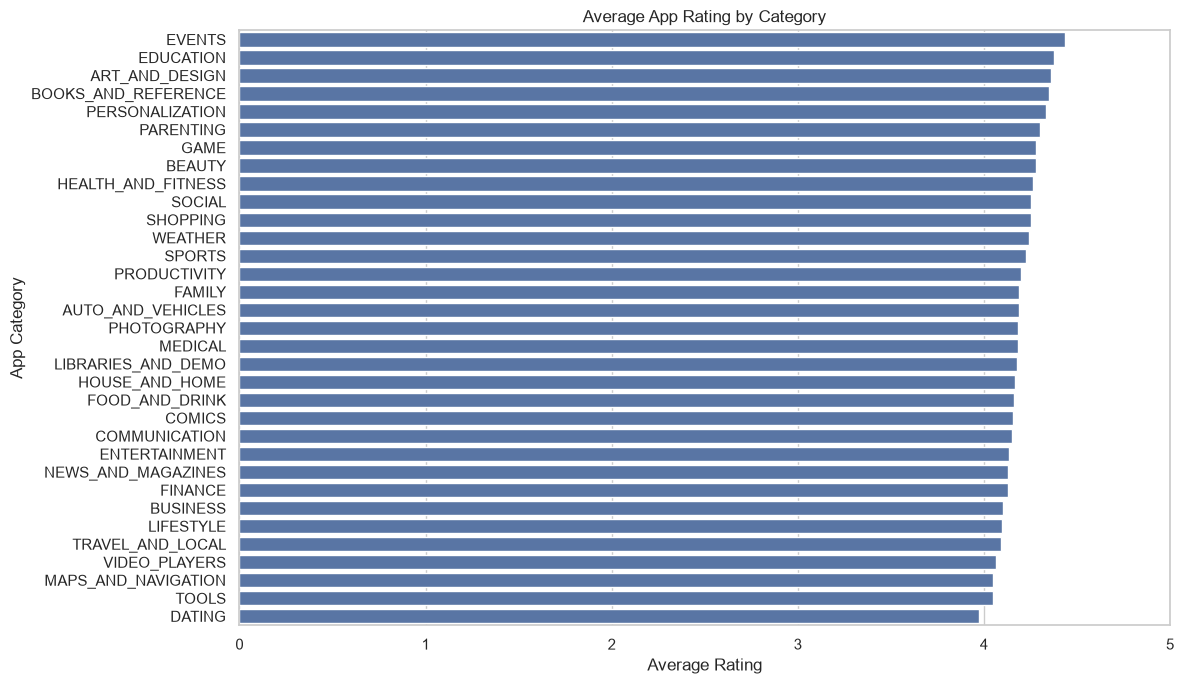

In [13]:
avg_rating_category = (
    apps_clean.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average App Rating by Category:")
display(avg_rating_category.to_frame("Average Rating").round(2))

plt.figure(figsize=(12, 7))
sns.barplot(
    x=avg_rating_category.values,
    y=avg_rating_category.index
)

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("App Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### Observation

The bar chart compares the average app ratings across Google Play Store categories. Categories with higher average ratings have better average user ratings, whereas categories with lower average ratings may indicate comparatively lower user satisfaction.

The results help identify differences in rating patterns among categories. However, average ratings alone do not explain the reasons behind these differences.

### 10.App Size vs. Number of Installs Analysis

App size can influence downloading decisions because larger applications require more storage space and data. The number of installs provides an estimate of an application's popularity.

In this analysis, a scatter plot is used to examine the relationship between app size and the number of installs. Since app sizes may be recorded as values such as `MB`, `kB`, or `Varies with device`, the size information must first be converted into a numerical format.

The correlation coefficient is also calculated to measure the strength and direction of the linear relationship between app size and installs.

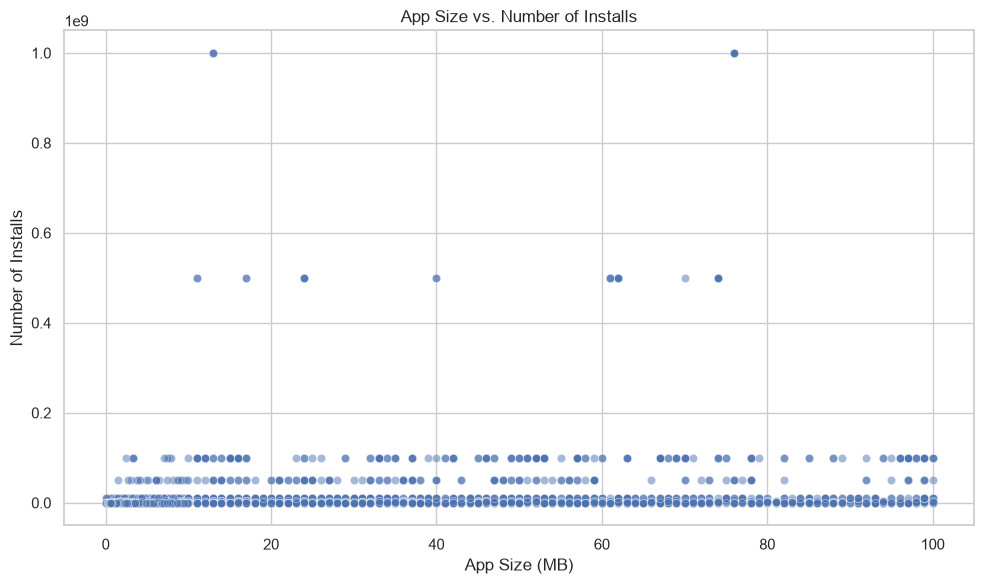

Correlation between App Size and Installs: 0.167
Number of apps analyzed: 7424


In [14]:
size_data = apps_clean.copy()

def convert_size(size):
    size = str(size).strip()

    if size.endswith("M"):
        return float(size[:-1])
    elif size.endswith("k"):
        return float(size[:-1]) / 1024
    else:
        return np.nan

size_data["Size_MB"] = size_data["Size"].apply(convert_size)

size_data = size_data.dropna(subset=["Size_MB", "Installs"])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=size_data,
    x="Size_MB",
    y="Installs",
    alpha=0.5
)

plt.title("App Size vs. Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")
plt.tight_layout()
plt.show()

correlation = size_data["Size_MB"].corr(size_data["Installs"])

print("Correlation between App Size and Installs:",
      round(correlation, 3))
print("Number of apps analyzed:", len(size_data))

### Observation

The scatter plot visualizes the relationship between app size and the number of installs. Each point represents an application, allowing us to observe patterns and variations in app popularity across different sizes.

The correlation coefficient indicates the direction and strength of the linear relationship. A value close to `+1` indicates a strong positive relationship, a value close to `-1` indicates a strong negative relationship, and a value close to `0` indicates a weak linear relationship.

The analysis considers only applications with valid numerical size and installation values. Correlation does not imply causation.

### 11.Free vs. Paid App Distribution Analysis

Applications on the Google Play Store can be classified as free or paid based on their listed prices. Free apps can be installed without an upfront purchase, while paid apps require users to pay before downloading.

In this analysis, applications are grouped according to their price. A count plot is used to compare the number of free and paid applications.

Understanding this distribution helps reveal the dominant pricing model in the Android app market.

Free vs. Paid Applications:


,Number of Apps
App_Type,
Free,8279
Paid,613


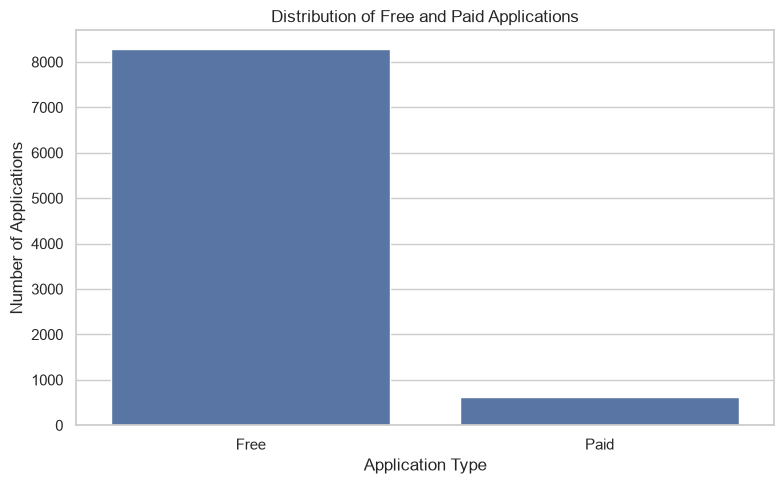

Free apps: 8279
Paid apps: 613


In [15]:
apps_clean["App_Type"] = np.where(
    apps_clean["Price"] == 0,
    "Free",
    "Paid"
)

app_type_counts = apps_clean["App_Type"].value_counts()

print("Free vs. Paid Applications:")
display(app_type_counts.to_frame("Number of Apps"))

plt.figure(figsize=(8, 5))
sns.countplot(
    data=apps_clean,
    x="App_Type",
    order=["Free", "Paid"]
)

plt.title("Distribution of Free and Paid Applications")
plt.xlabel("Application Type")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

print("Free apps:", app_type_counts.get("Free", 0))
print("Paid apps:", app_type_counts.get("Paid", 0))

### Observation

The bar chart compares the number of free and paid applications in the dataset. The taller bar indicates the more common pricing model.

This analysis helps determine whether the Google Play Store dataset is dominated by free or paid applications. The results provide context for the subsequent analysis of paid app prices and estimated revenue.

### 12.Price Distribution Analysis of Paid Applications

Paid applications generate revenue by charging users an upfront purchase price. Studying their price distribution helps us understand the pricing strategies used by developers in the Google Play Store.

In this analysis, free applications are excluded, and the prices of paid applications are examined using a histogram. Descriptive statistics are also calculated to summarize the minimum, maximum, average, and median prices.

This analysis helps identify common pricing ranges and unusually expensive applications.

Number of Paid Applications: 613

Price Statistics:


,Price
count,613.00
mean,13.97
std,60.21
min,0.99
25%,1.99
50%,2.99
75%,4.99
max,400.00


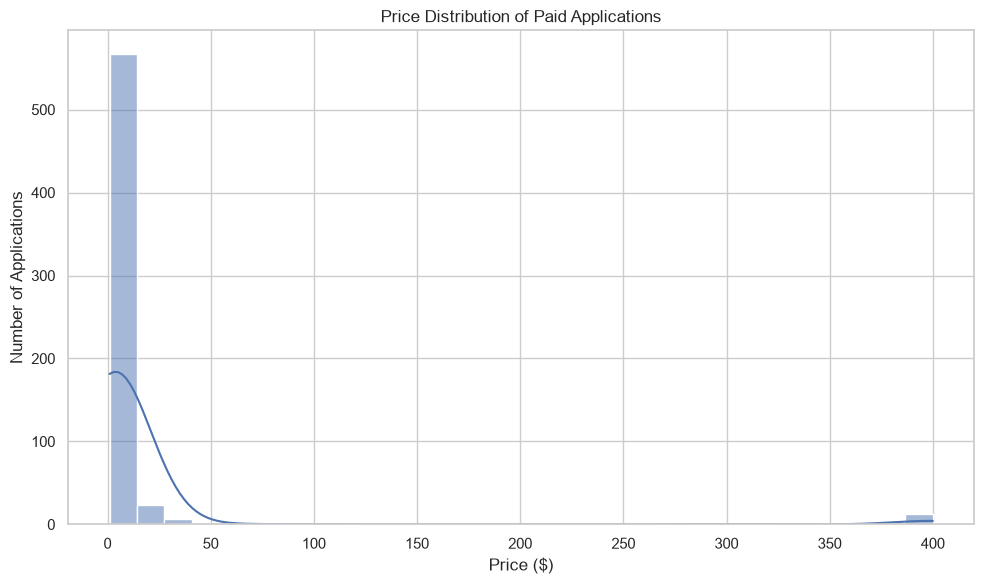

In [16]:
paid_apps = apps_clean[apps_clean["Price"] > 0].copy()

print("Number of Paid Applications:", len(paid_apps))
print("\nPrice Statistics:")
display(paid_apps["Price"].describe().to_frame("Price").round(2))

plt.figure(figsize=(10, 6))
sns.histplot(
    data=paid_apps,
    x="Price",
    bins=30,
    kde=True
)

plt.title("Price Distribution of Paid Applications")
plt.xlabel("Price ($)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

### Observation

The histogram illustrates the price distribution of paid applications. It helps identify the price ranges in which applications are concentrated and whether a small number of applications have unusually high prices.

The descriptive statistics summarize the pricing pattern using the mean, median, minimum, and maximum values. The mean may be influenced by expensive applications, so the median is also useful when interpreting typical app prices.

### 13.Estimated Revenue by App Category

Revenue estimation helps compare the potential earnings of paid applications across different Google Play Store categories.

In this analysis, estimated revenue is calculated by multiplying an application's listed price by its reported number of installs. The estimated revenue values are then grouped by category and aggregated to compare categories.

This provides an approximate comparison of revenue potential across categories. However, the calculation assumes that every reported install represents a purchase, so the results should not be interpreted as actual developer earnings.

Estimated Revenue by App Category:


,Estimated Revenue ($)
Category,
FAMILY,1.857743e+08
LIFESTYLE,5.758394e+07
GAME,4.098684e+07
FINANCE,2.572664e+07
PHOTOGRAPHY,8.941050e+06
MEDICAL,8.371355e+06
PERSONALIZATION,7.786310e+06
TOOLS,5.462910e+06
SPORTS,4.706154e+06


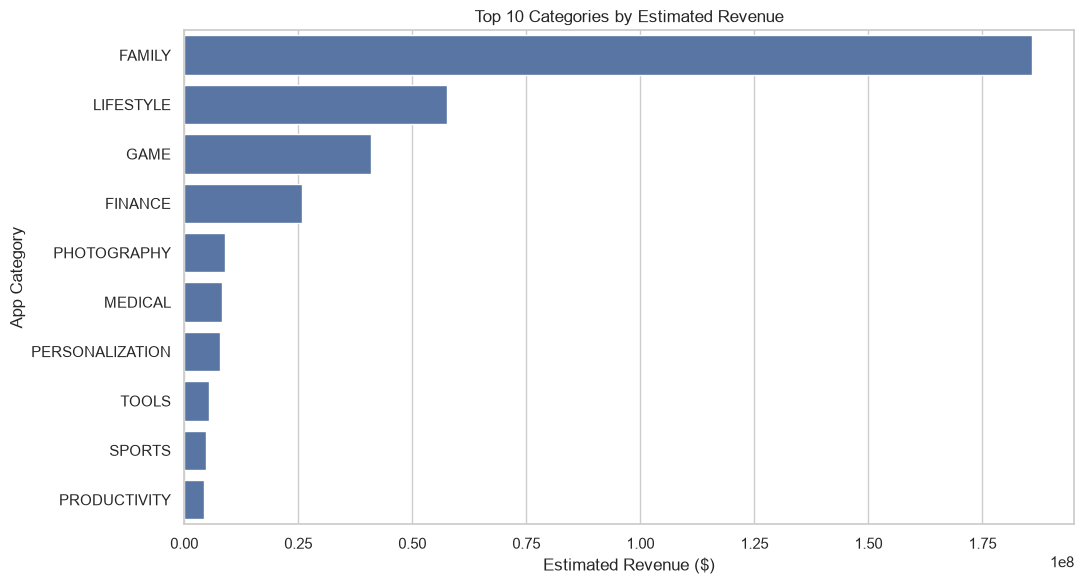

In [17]:
# Select paid applications
paid_apps = apps_clean[apps_clean["Price"] > 0].copy()

# Estimate revenue for each application
paid_apps["Estimated_Revenue"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

# Calculate estimated revenue by category
revenue_by_category = (
    paid_apps.groupby("Category")["Estimated_Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Estimated Revenue by App Category:")
display(
    revenue_by_category.to_frame("Estimated Revenue ($)").round(2)
)

# Visualize the top 10 categories
top_revenue = revenue_by_category.head(10)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=top_revenue.values,
    y=top_revenue.index
)

plt.title("Top 10 Categories by Estimated Revenue")
plt.xlabel("Estimated Revenue ($)")
plt.ylabel("App Category")
plt.tight_layout()
plt.show()

### Observation

The bar chart compares the top 10 categories by estimated revenue from paid applications. Categories with larger estimated revenue values show a higher calculated revenue potential based on listed prices and reported installs.

These estimates help compare categories, but they do not represent actual earnings because install counts may include downloads that did not result in purchases, and the calculation does not account for refunds, platform fees, or other expenses.

### 14.User Review Sentiment Analysis

Sentiment analysis is a Natural Language Processing (NLP) technique used to identify the emotional tone of text. In the Google Play Store dataset, user reviews provide valuable information about customer experiences and satisfaction.

In this analysis, the `Translated_Review` column is used to examine review text. The TextBlob library calculates a sentiment polarity score ranging from -1 to +1.

- **Positive:** Polarity greater than 0.
- **Negative:** Polarity less than 0.
- **Neutral:** Polarity equal to 0.

The reviews are classified into these three categories, and their distribution is visualized to understand the overall sentiment of users.

In [20]:
reviews_clean = reviews.copy()

# Remove duplicate review records
reviews_clean = reviews_clean.drop_duplicates()

# Remove rows without review text
reviews_clean = reviews_clean.dropna(
    subset=["Translated_Review"]
)

print("Original review records:", len(reviews))
print("Cleaned review records:", len(reviews_clean))
print("Remaining missing reviews:",
      reviews_clean["Translated_Review"].isnull().sum())

Original review records: 64295
Cleaned review records: 29692
Remaining missing reviews: 0


,App,Translated_Review,Polarity,Sentiment
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,1.00,Positive
1,10 Best Foods for You,This help eating healthy exercise regular basis,0.25,Positive
3,10 Best Foods for You,Works great especially going grocery store,0.40,Positive
4,10 Best Foods for You,Best idea us,1.00,Positive
5,10 Best Foods for You,Best way,1.00,Positive
6,10 Best Foods for You,Amazing,0.60,Positive
8,10 Best Foods for You,"Looking forward app,",0.00,Neutral
9,10 Best Foods for You,It helpful site ! It help foods get !,0.00,Neutral
10,10 Best Foods for You,good you.,0.70,Positive
11,10 Best Foods for You,Useful information The amount spelling errors ...,0.20,Positive


Review Sentiment Counts:


,Number of Reviews
Sentiment,
Positive,19014
Negative,6322
Neutral,4356


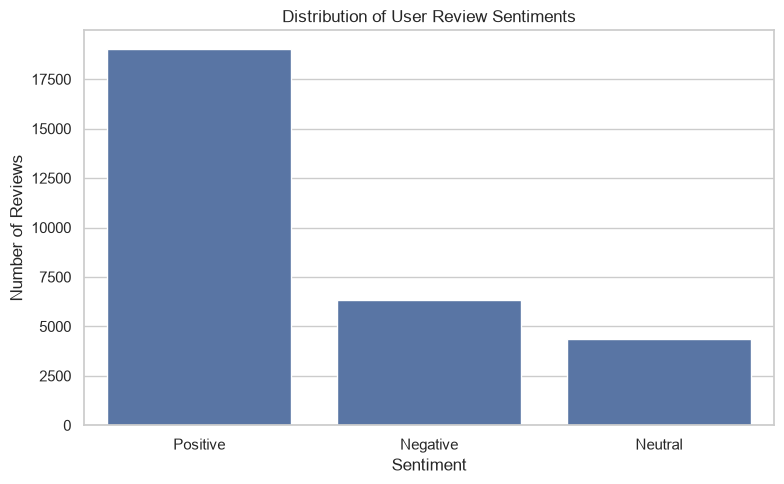

In [21]:
from textblob import TextBlob

# Remove reviews with missing text
reviews_sentiment = reviews_clean.dropna(
    subset=["Translated_Review"]
).copy()

# Calculate sentiment polarity
reviews_sentiment["Polarity"] = (
    reviews_sentiment["Translated_Review"]
    .apply(lambda review: TextBlob(str(review)).sentiment.polarity)
)

# Classify sentiment
def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

reviews_sentiment["Sentiment"] = (
    reviews_sentiment["Polarity"].apply(classify_sentiment)
)

# Display sample results
display(
    reviews_sentiment[
        ["App", "Translated_Review", "Polarity", "Sentiment"]
    ].head(10)
)

# Count each sentiment category
sentiment_counts = (
    reviews_sentiment["Sentiment"]
    .value_counts()
    .reindex(["Positive", "Negative", "Neutral"], fill_value=0)
)

print("Review Sentiment Counts:")
display(sentiment_counts.to_frame("Number of Reviews"))

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Distribution of User Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Observation

The sentiment analysis classifies user reviews as positive, negative, or neutral based on their polarity scores. The bar chart compares the number of reviews in each sentiment category.

The most frequent sentiment indicates the dominant sentiment among the analyzed reviews. This analysis provides an overview of user opinions, although automated sentiment classification may not correctly interpret sarcasm, context, or every expression.

### 15.Sentiment Analysis Across App Categories

Different app categories may receive different levels of user satisfaction depending on their features, performance, and usability. Comparing review sentiment across categories helps identify these differences.

In this analysis, the sentiment labels generated in the previous step are combined with app category information using the app name as the common field. The number of positive, negative, and neutral reviews is then grouped by category and visualized using a stacked bar chart.

This analysis helps compare user opinions across categories. However, the results depend on the available reviews and the accuracy of the sentiment classification method.

Sentiment Counts by App Category:


Sentiment,Positive,Negative,Neutral
Category,,,
ART_AND_DESIGN,240,54,60
AUTO_AND_VEHICLES,230,17,36
BEAUTY,176,60,81
BOOKS_AND_REFERENCE,427,84,106
BUSINESS,379,115,163
COMICS,39,1,5
COMMUNICATION,521,179,158
DATING,669,228,190
EDUCATION,488,75,81


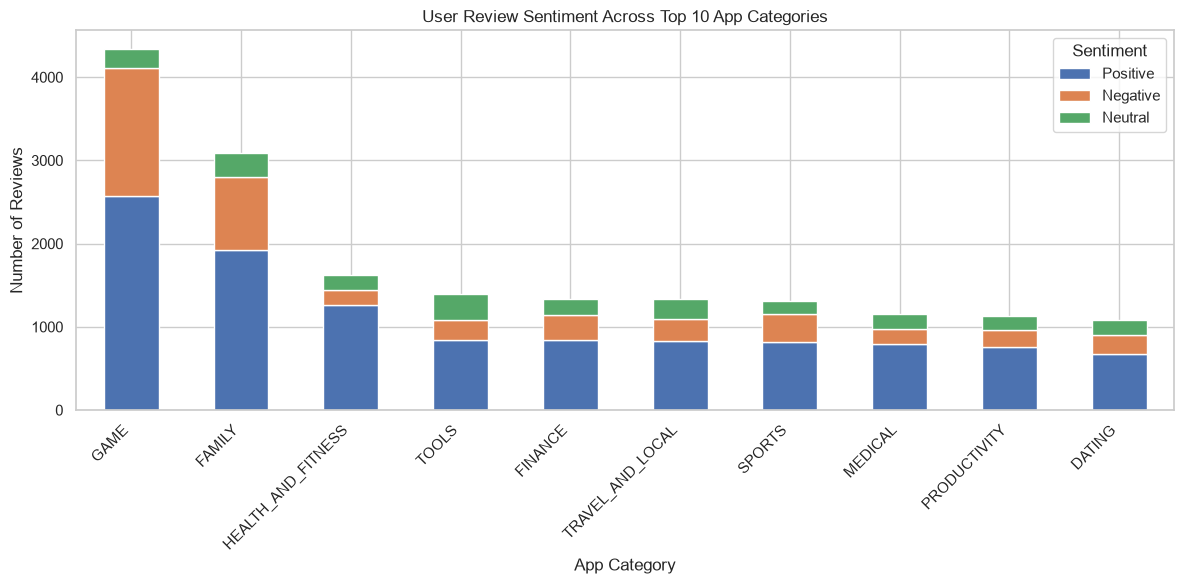

In [22]:
# Select app names and categories
app_categories = apps_clean[["App", "Category"]].drop_duplicates()

# Merge reviews with app categories
category_reviews = reviews_sentiment.merge(
    app_categories,
    on="App",
    how="inner"
)

# Count sentiments by category
sentiment_by_category = pd.crosstab(
    category_reviews["Category"],
    category_reviews["Sentiment"]
)

# Ensure all sentiment columns exist
sentiment_by_category = sentiment_by_category.reindex(
    columns=["Positive", "Negative", "Neutral"],
    fill_value=0
)

print("Sentiment Counts by App Category:")
display(sentiment_by_category)

# Visualize the top 10 categories by total review count
top_categories = (
    sentiment_by_category.sum(axis=1)
    .sort_values(ascending=False)
    .head(10)
    .index
)

sentiment_by_category.loc[top_categories].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("User Review Sentiment Across Top 10 App Categories")
plt.xlabel("App Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

### Observation

The stacked bar chart compares the number of positive, negative, and neutral reviews across the ten categories with the highest total review counts.

The distribution highlights differences in user feedback among app categories. Categories with more positive reviews have a greater number of favorable opinions, while categories with more negative reviews may have more reported dissatisfaction. Since the chart displays counts rather than percentages, categories with more reviews may naturally have taller bars.

The findings reflect the available reviews and should be interpreted with consideration for differences in review volume.

### 16.Interactive Visualization Using Plotly

Plotly is a Python visualization library that creates interactive charts. Unlike static charts, Plotly visualizations allow users to hover over data points, zoom in, and explore values.

In this section, an interactive bar chart is created to compare average app ratings across Google Play Store categories.

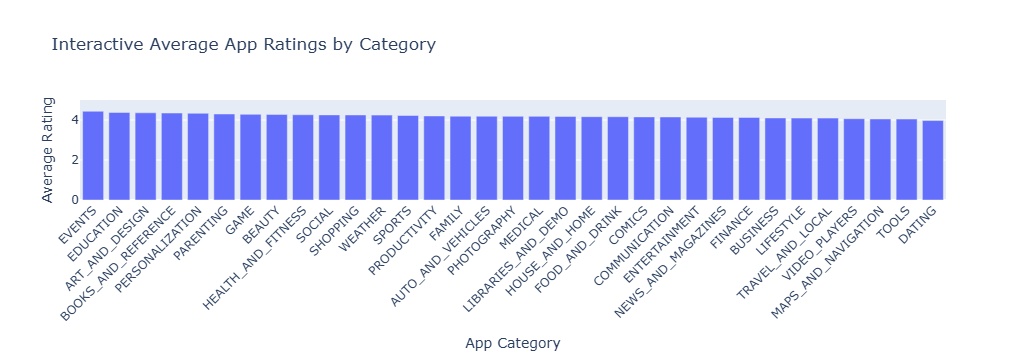

In [24]:
import plotly.express as px

avg_rating = (
    apps_clean.groupby("Category", as_index=False)["Rating"]
    .mean()
    .dropna()
    .sort_values("Rating", ascending=False)
)

fig = px.bar(
    avg_rating,
    x="Category",
    y="Rating",
    title="Interactive Average App Ratings by Category",
    labels={
        "Category": "App Category",
        "Rating": "Average Rating"
    },
    hover_data={"Rating": ":.2f"}
)

fig.update_layout(
    xaxis_tickangle=-45,
    yaxis_range=[0, 5]
)

fig.show()

### Observation

The interactive Plotly chart allows users to compare average app ratings across categories and inspect individual values using hover interactions. It complements the static Matplotlib and Seaborn charts by making the analysis easier to explore.

## 17.Key Insights for Android App Developers

This analysis identifies potential opportunities in the Android app market by examining category competition, average app ratings, and user review sentiment. These insights help developers understand market representation, user satisfaction, and areas that may require improvement. The results can support informed decisions when selecting an app category and planning features. The findings are based on the Google Play Store dataset and should be considered alongside market demand and business feasibility.

### App Market Saturation Analysis

Top 10 Categories by Number of Apps:


,App Count
Category,
FAMILY,1718
GAME,1074
TOOLS,734
PRODUCTIVITY,334
FINANCE,317
PERSONALIZATION,310
COMMUNICATION,307
LIFESTYLE,305
PHOTOGRAPHY,304



Bottom 10 Categories by Number of Apps:


,App Count
Category,
BEAUTY,42
EVENTS,45
PARENTING,50
COMICS,58
ART_AND_DESIGN,62
LIBRARIES_AND_DEMO,65
HOUSE_AND_HOME,68
AUTO_AND_VEHICLES,73
WEATHER,75


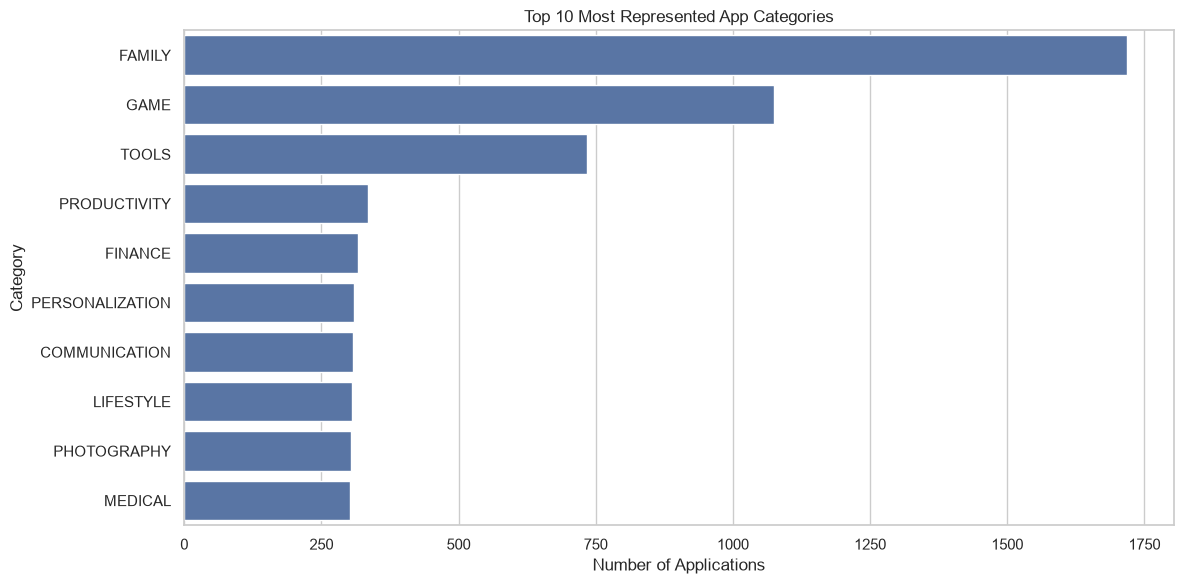

In [25]:
category_counts = apps_clean["Category"].value_counts()

print("Top 10 Categories by Number of Apps:")
display(
    category_counts.head(10).to_frame("App Count")
)

print("\nBottom 10 Categories by Number of Apps:")
display(
    category_counts.tail(10).sort_values()
    .to_frame("App Count")
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts.head(10).values,
    y=category_counts.head(10).index
)

plt.title("Top 10 Most Represented App Categories")
plt.xlabel("Number of Applications")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Average App Ratings by Category

Top 10 Categories by Average Rating:


,Average_Rating,Rated_App_Count
Category,,
EVENTS,4.44,45
EDUCATION,4.38,129
ART_AND_DESIGN,4.36,62
BOOKS_AND_REFERENCE,4.35,177
PERSONALIZATION,4.33,310
PARENTING,4.30,50
GAME,4.28,1074
BEAUTY,4.28,42
HEALTH_AND_FITNESS,4.26,262



Bottom 10 Categories by Average Rating:


,Average_Rating,Rated_App_Count
Category,,
DATING,3.97,159
TOOLS,4.05,734
MAPS_AND_NAVIGATION,4.05,124
VIDEO_PLAYERS,4.06,160
TRAVEL_AND_LOCAL,4.09,205
LIFESTYLE,4.10,305
BUSINESS,4.10,270
FINANCE,4.13,317
NEWS_AND_MAGAZINES,4.13,214


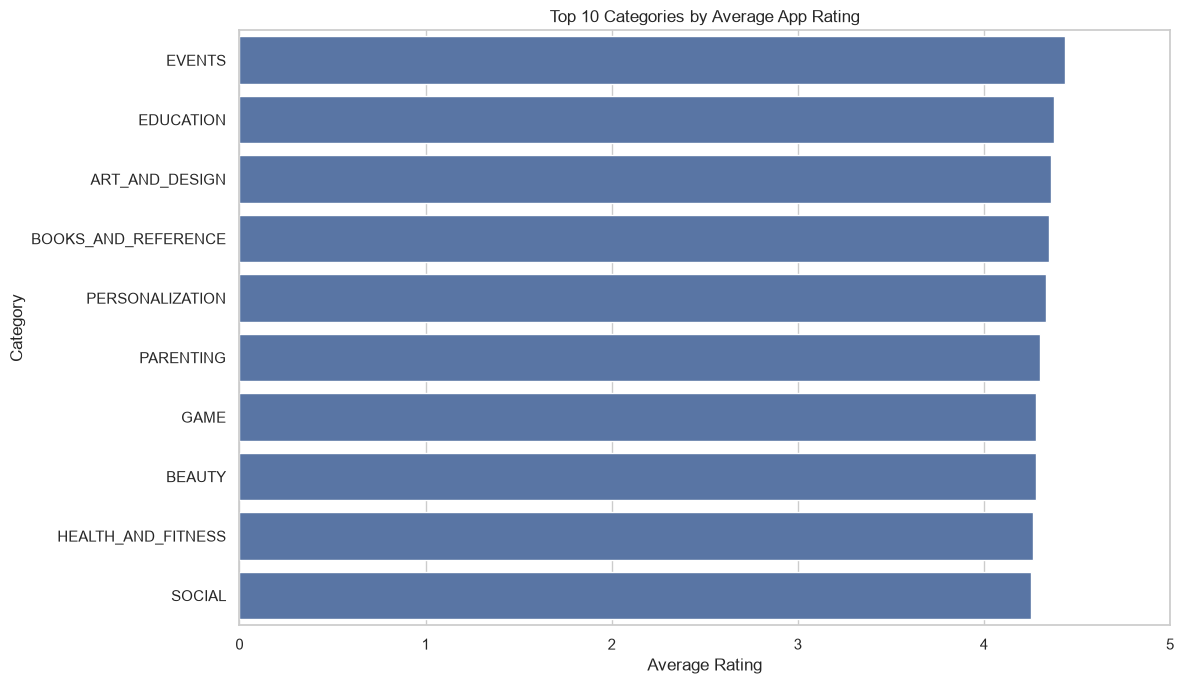

In [26]:
rating_by_category = (
    apps_clean.groupby("Category")
    .agg(
        Average_Rating=("Rating", "mean"),
        Rated_App_Count=("Rating", "count")
    )
    .dropna(subset=["Average_Rating"])
    .sort_values("Average_Rating", ascending=False)
)

print("Top 10 Categories by Average Rating:")
display(rating_by_category.head(10).round(2))

print("\nBottom 10 Categories by Average Rating:")
display(rating_by_category.tail(10).sort_values(
    "Average_Rating"
).round(2))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=rating_by_category.reset_index(),
    x="Average_Rating",
    y="Category",
    order=rating_by_category.head(10).index
)

plt.title("Top 10 Categories by Average App Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### User Sentiment Analysis by Category

Top 10 Categories by Positive Sentiment Percentage:


Sentiment,Positive,Negative,Neutral
Category,,,
COMICS,86.67,2.22,11.11
AUTO_AND_VEHICLES,81.27,6.01,12.72
EVENTS,78.85,10.26,10.90
HEALTH_AND_FITNESS,77.85,10.98,11.17
EDUCATION,75.78,11.65,12.58
FOOD_AND_DRINK,74.10,13.38,12.52
LIBRARIES_AND_DEMO,71.39,15.36,13.25
PARENTING,70.70,8.98,20.31
PERSONALIZATION,69.51,14.57,15.92



Top 10 Categories by Negative Sentiment Percentage:


Sentiment,Positive,Negative,Neutral
Category,,,
GAME,59.09,35.47,5.43
SOCIAL,55.52,28.74,15.73
FAMILY,62.22,28.39,9.39
ENTERTAINMENT,59.61,25.76,14.63
VIDEO_PLAYERS,56.75,25.46,17.79
SPORTS,62.36,25.17,12.47
NEWS_AND_MAGAZINES,60.71,23.33,15.96
FINANCE,62.95,22.46,14.60
DATING,61.55,20.98,17.48


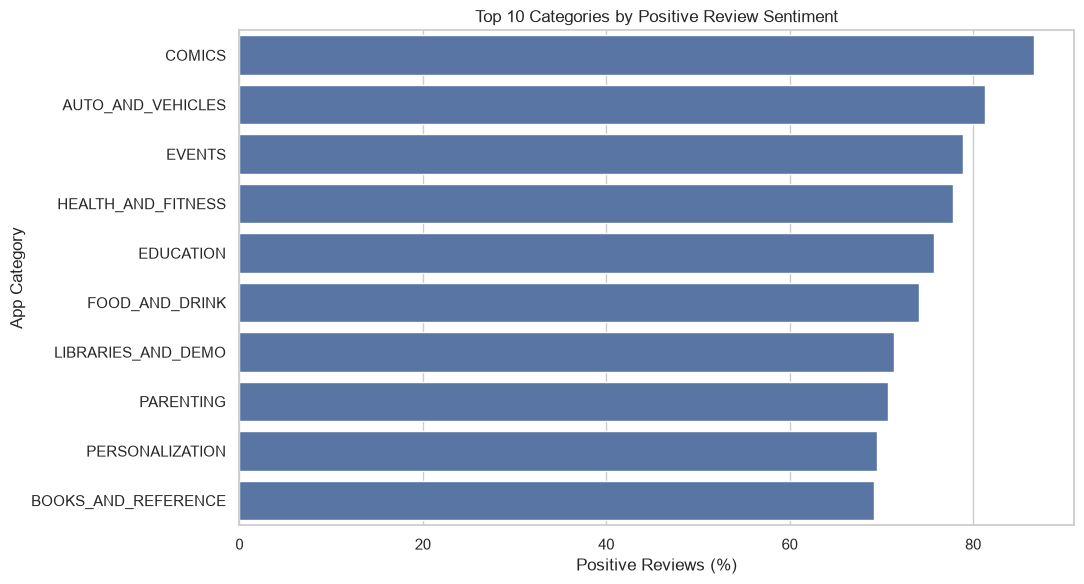

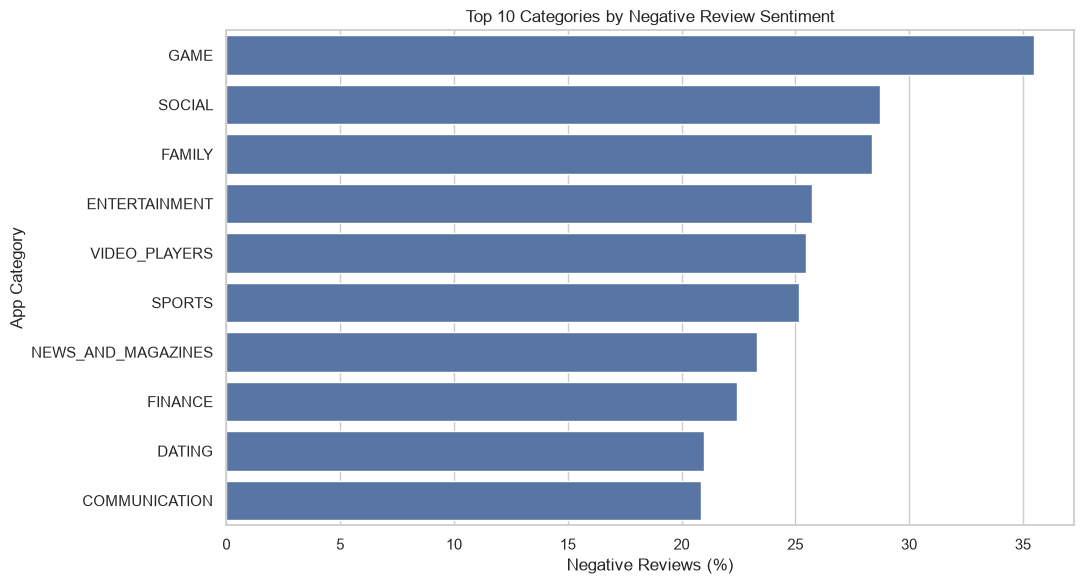

In [28]:
# Map each app to its category
app_category_map = apps_clean[["App", "Category"]].drop_duplicates()

# Merge category information with classified reviews
category_sentiment = reviews_sentiment.merge(
    app_category_map,
    on="App",
    how="inner"
)

# Count sentiments by category
sentiment_counts = pd.crosstab(
    category_sentiment["Category"],
    category_sentiment["Sentiment"]
).reindex(
    columns=["Positive", "Negative", "Neutral"],
    fill_value=0
)

# Calculate percentages within each category
sentiment_percent = sentiment_counts.div(
    sentiment_counts.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

# Require at least 20 reviews for a more useful comparison
review_totals = sentiment_counts.sum(axis=1)
eligible_categories = review_totals[review_totals >= 20].index

sentiment_counts = sentiment_counts.loc[eligible_categories]
sentiment_percent = sentiment_percent.loc[eligible_categories]

print("Top 10 Categories by Positive Sentiment Percentage:")
display(
    sentiment_percent.sort_values(
        "Positive", ascending=False
    ).head(10).round(2)
)

print("\nTop 10 Categories by Negative Sentiment Percentage:")
display(
    sentiment_percent.sort_values(
        "Negative", ascending=False
    ).head(10).round(2)
)

# Visualize sentiment percentages
top_positive = sentiment_percent.sort_values(
    "Positive", ascending=False
).head(10)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=top_positive["Positive"].values,
    y=top_positive.index
)
plt.title("Top 10 Categories by Positive Review Sentiment")
plt.xlabel("Positive Reviews (%)")
plt.ylabel("App Category")
plt.tight_layout()
plt.show()

top_negative = sentiment_percent.sort_values(
    "Negative", ascending=False
).head(10)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=top_negative["Negative"].values,
    y=top_negative.index
)
plt.title("Top 10 Categories by Negative Review Sentiment")
plt.xlabel("Negative Reviews (%)")
plt.ylabel("App Category")
plt.tight_layout()
plt.show()

## Key Insights for Android App Developers

**1. Market Competition and App Category Saturation**

The FAMILY category has the highest number of applications (1,718), followed by GAME (1,074) and TOOLS (734), indicating strong market representation and potential competition. In contrast, categories such as BEAUTY (42), EVENTS (45), and PARENTING (50) have fewer applications. Developers entering highly represented categories should focus on unique features and differentiation, while less represented categories may be worth exploring after evaluating user demand and market potential.

**2. User Satisfaction Based on Average Ratings**

The EVENTS category has the highest average rating (4.44), followed by EDUCATION (4.38) and ART_AND_DESIGN (4.36). These results suggest relatively high user satisfaction among rated applications in these categories. Developers can study successful applications in these areas to understand user expectations, improve application quality, and develop user-friendly features. However, average ratings alone do not determine the commercial success of a new application.

**3. User Review Sentiment and Improvement Opportunities**

Sentiment analysis reveals that COMICS has the highest percentage of positive reviews (86.67%), followed by AUTO_AND_VEHICLES (81.27%) and EVENTS (78.85%). Meanwhile, GAME (35.47%), SOCIAL (28.74%), and FAMILY (28.39%) have the highest percentages of negative reviews. These findings suggest that developers should examine user complaints in categories with higher negative sentiment to identify opportunities for improving app performance, usability, and overall user experience.

## Conclusion

This project explored the Google Play Store dataset using Python and data analysis libraries such as Pandas, NumPy, Matplotlib, and Seaborn. Data cleaning and preprocessing were performed to improve data quality and prepare the datasets for analysis.

Exploratory Data Analysis was used to examine app category distribution, ratings, app size, installations, pricing, and estimated revenue. Sentiment analysis using TextBlob provided additional insights into user opinions expressed in application reviews.

The analysis demonstrates how data analytics techniques can help identify patterns in the Android app market and support a better understanding of application popularity, pricing strategies, and user feedback.

Overall, this project provided practical experience in data preprocessing, visualization, statistical analysis, and basic Natural Language Processing (NLP). The findings are limited by the quality and completeness of the dataset, and estimated revenue and automated sentiment classifications should be interpreted with appropriate caution.